In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

### Results

In [ ]:
resdir = 'simulations/results/sim_params/nodes_10_to_30_stepsize_1/n_graphs_3'

res_df = pd.read_csv(f'{resdir}/results_combined.csv', header=[0,1], index_col=0)

# group methods
method_group = {}
for method in list(res_df.index):
    if 'toper' in method:
        method_group[method] = 'TopER'
    elif 'kernel' in method:
        method_group[method] = 'Kernel'
    elif 'embedding' in method or 'spectral_zoo' == method:
        method_group[method] = 'Embeddings'
    elif 'divcurves' in method:
        method_group[method] = 'Diversity Curves'
    elif 'div_function' in method or 'one_scale' in method:
        method_group[method] = 'Diversity Profile'
    elif 'persistent_homology' in method:
        method_group[method] = 'Persistent Homology'

        
res_df['group'] = [method_group[method] for method in list(res_df.index)]

#rename rows, only relevant ones, rest will be dropped
new_names = {
        # 'divcurves_funs_diffs_shortest_path_distance': 'shortest path area between curves',
        'divcurves_shortest_path_distance': 'Shortest Path',
        # 'divcurves_mds_funs_diffs_shortest_path_distance': 'shortest path area between curves MDS',
        # 'divcurves_mds_shortest_path_distance': 'shortest path MDS',
        'divcurves_pca_shortest_path_distance': 'Shortest Path PCA',
        'div_function_shortest_path_distance': 'Profile Shortest Path', 
        'graph_embedding_netLSD': 'NetLSD',
        'graph_embedding_graph2vec': 'Graph2Vec', 
        'graph_embedding_feathergraph': 'FEATHER',
        'kernel_shortest_path': 'Kernel Shortest Path', 
        'kernel_mds_shortest_path': 'Kernel Shortest Path MDS',
        'kernel_pyramid_match': 'Kernel Pyramid Match', 
        'kernel_mds_pyramid_match': 'Kernel Pyramid Match MDS',
        'kernel_neighborhood_hash': 'Kernel Neighbourhood Hash', 
        'kernel_mds_neighborhood_hash': 'Kernel Neighbourhood Hash MDS',
        # 'kernel_subtree_wl': 'Kernel Subtree WL', 
        # 'kernel_odd_sth': 'Kernel ODD-STh', 
        # 'kernel_mds_odd_sth': 'Kernel ODD-STh MDS',
        # 'kernel_propagation': 'Kernel Propagation', 
        # 'kernel_mds_propagation': 'Kernel Propagation MDS',
        # 'kernel_vertex_histogram': 'Kernel Vertex Histogram', 
        'kernel_weisfeiler_lehman': 'Kernel WL',
        'kernel_mds_weisfeiler_lehman': 'Kernel WL MDS', 
        'kernel_core_framework': 'Kernel Core Framework',
        'kernel_mds_core_framework': 'Kernel Core Framework MDS',
        'kernel_weisfeiler_lehman_optimal_assignment': 'Kernel WL Optimal Assignment',
        'kernel_mds_weisfeiler_lehman_optimal_assignment': 'Kernel WL Optimal Assignment MDS', 
    #    'toper_degree_super',
        'toper_degree_sub': 'TopER Degree', 
    #    'toper_degree_sub_super', 
    #    'toper_popularity_super',
        'toper_popularity_sub': 'TopER Popularity', 
    #    'toper_popularity_sub_super',
    #    'toper_forricci_super', 
        'toper_forricci_sub': 'TopER Forricci',
    #    'toper_forricci_sub_super', 
    #    'toper_olricci_super', 
        'toper_olricci_sub': 'TopER Olricci',
    #    'toper_olricci_sub_super', 
    #    'toper_closeness_super',
        'toper_closeness_sub': 'TopER Closeness', 
    #    'toper_closeness_sub_super', 
        'toper_all_sub': 'TopER All Filtrations',
        'spectral_zoo': 'Spectral Zoo',

        # 'persistent_homology_degree': 'PH Degree',

        # 'persistent_homology_ollivier_ricci_curvature': 'PH Olricci',

        # 'persistent_homology_forman_ricci_curvature': 'PH Fricci',

        # 'persistent_homology_laplacian': 'PH Laplacian', 

        # 'persistent_homology_vietoris_rips': 'PH Vietoris Rips',

        # 'persistent_homology_alpha_complex': 'PH Alpha Complex',

}

df = res_df.rename(new_names)
df = df.loc[list(new_names.values()),:]

# add group to multiindex
df = df.set_index('group', append = True).swaplevel(0,1)
df.index.rename(['Group', 'Method'], inplace = True)




configs = pd.read_csv(f'{resdir}/configs.csv', header=[0], index_col=0)

scores = ['acc', 'silh', 'db', 'ch', 'ari_agglo', 'ari_kmeans']
scores_asc = {'acc': False, 'silh': False, 'ari_agglo': False, 'db': True,'ch': False, 'ari_kmeans': False}


# results_latex = pd.DataFrame(index=res_copy.index)
results_latex_dfs = {}
models = list(np.unique(df.columns.get_level_values(0)))

for model in models:
    results_latex_model = {}
    # sort wrt to accuracy, in groups
    df_model = df.groupby(level=0, sort=False).apply(lambda x: x.sort_values((model, 'acc_mean'), ascending=False)).droplevel(0)
    res_copy = df_model.copy()
    for score in scores:
        mean_col = (model, f'{score}_mean')
        std_col = (model, f'{score}_std')

        if mean_col in res_copy.columns and std_col in res_copy.columns:
            results_latex_model[score] = res_copy[mean_col].combine(
                res_copy[std_col],
                lambda m, s: '{:.3f}'.format(round(m, 3)) + ' $\\pm $ ' + '{:.3f}'.format(round(s, 3))
            )
    results_latex_df_model = pd.DataFrame.from_dict(results_latex_model)
    

# Bold the best mean for each score within each top-level group

    for score in scores:
        mean_col = (model, f"{score}_mean")
        display_col = (model, score)
        if mean_col in res_copy.columns:
            if not scores_asc[score]: 
                best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].max(),3)
            else:
                best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].min(),3)
            results_latex_df_model.loc[best_mask, score] = results_latex_df_model.loc[best_mask, score].apply(
                lambda x: f"\\textbf{{{x}}}"
            )
        else:
            print(f'{mean_col} not in dataframe?')

    #final adjustments latex df 
    results_latex_df_model.index.rename([None, 'Method'], inplace = True)
    new_cols = {
        'acc': 'Accuracy', 
        'silh': 'Silhouette Score', 
        'db': 'Davies-Bouldin', 
        'ch': 'Calinski-Harabasz', 
        'ari_kmeans': 'ARI k-means', 
        'ari_agglo': 'ARI agglomerative'
    }

    results_latex_df_model = results_latex_df_model.rename(columns=new_cols)
    results_latex_df_model.replace(to_replace='nan $\\pm $ nan', value='-', inplace=True)

    #save df in dict
    results_latex_dfs[model] = results_latex_df_model

for model in models:
    print(f'model: {model} with config' + configs.loc[(model, 'configurations')])
    print(results_latex_dfs[model].to_latex(multirow=False))

### Generating cluster score plot

In [49]:
resdir = 'simulations/results/sim_params/nodes_10_to_30_stepsize_1/n_graphs_3'
res_df = pd.read_csv(f'{resdir}/results_combined.csv', header=[0,1], index_col=0)
configs = pd.read_csv(f'{resdir}/configs.csv', header=[0], index_col=0)

divcurves_pca_shortest_path_distance
divcurves_pca_shortest_path_distance
divcurves_pca_shortest_path_distance
divcurves_pca_shortest_path_distance
graph_embedding_feathergraph
graph_embedding_feathergraph
graph_embedding_feathergraph
graph_embedding_netLSD
kernel_shortest_path
kernel_shortest_path
kernel_shortest_path
kernel_mds_core_framework
toper_forricci_sub
toper_degree_super
toper_popularity_super
toper_forricci_super


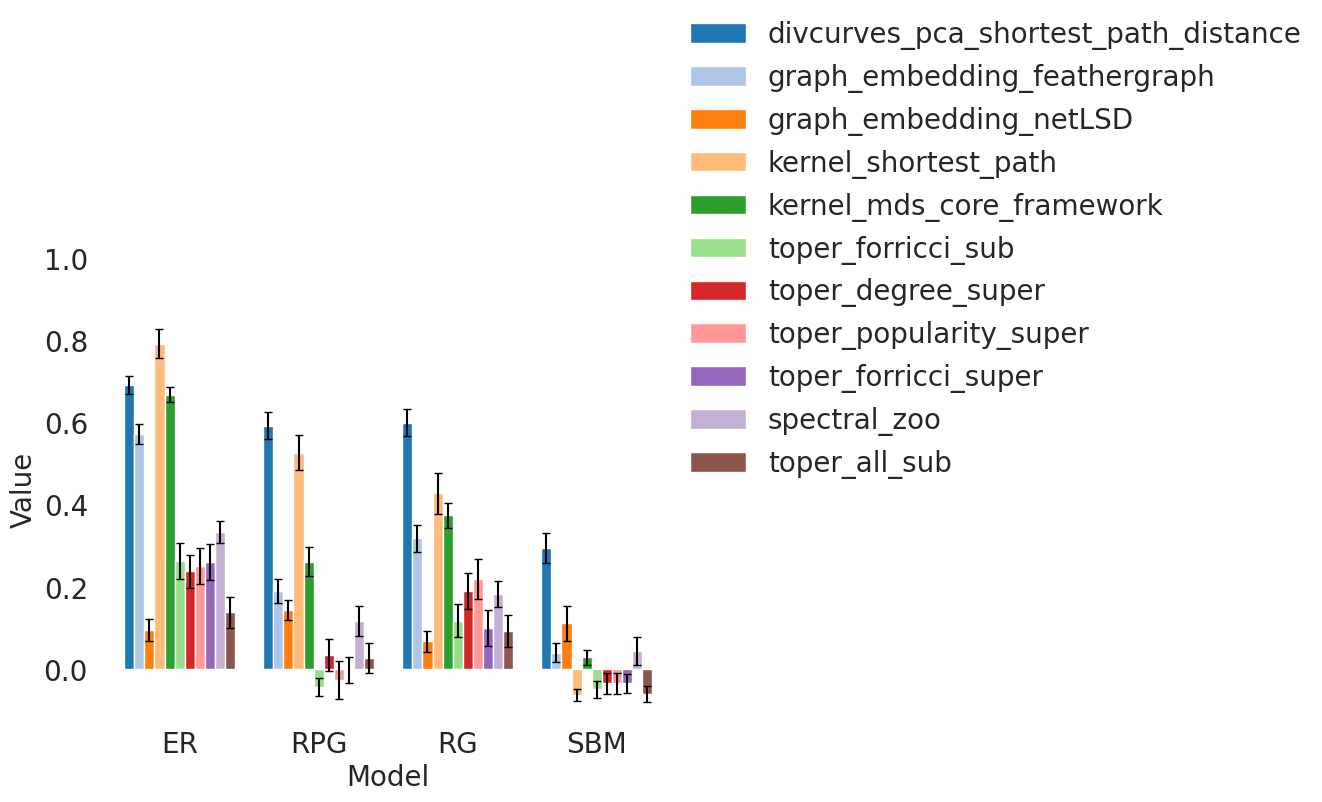

In [54]:
# models = list(np.unique(res_df_copy.columns.get_level_values(0)))
models = ['ER', 'RPG', 'RG', 'SBM']
score = 'silh'
baselines = [
    'divcurves',
     'graph_embedding', 
     'kernel', 
     'toper', 
    #  'persistent_homology'
     ]

best_baselines = {}
all_selected = []

res_df_copy = res_df.copy()
for baseline in baselines:
    selected = set()
    for model in models:
        best = res_df_copy.loc[res_df_copy.index.str.contains(baseline),(model, f'{score}_mean')].nlargest(1).index.values[0]
        print(best)
        selected.add(best)
        all_selected.append(best)
    best_baselines[baseline] = selected

all_selected.append('spectral_zoo')
unique = []
for i, element in enumerate(all_selected):
    if element not in all_selected[:i]:
        unique.append(element)

unique.append('toper_all_sub')
selected = res_df.loc[unique]


y=selected.loc[:, (models, [f'{score}_mean'])].droplevel(level=1, axis=1)
y_err = selected.loc[:, (models, [f'{score}_std'])].droplevel(level=1, axis=1)

# Assuming y and y_err are DataFrames with columns ['ER', 'BA', 'SBM']
# and multiple rows

fig, ax = plt.subplots(figsize=(10, 6))

# Get the models (column names)
models = y.columns  # ['ER', 'BA', 'SBM']
n_rows = len(y)
x_positions = np.arange(len(models))

# Width for offsetting errorbars within each model group
bar_width = 0.8 / n_rows  # Adjust divisor to control spacing

# Colors for each row
colors = plt.cm.tab20(X=range(n_rows))

bars = {}

# Plot errorbars for each row
for row_idx, row_name in enumerate(y.index):
    offsets = x_positions + (row_idx - n_rows/2 + 0.5) * bar_width
    ax.errorbar(
        offsets, 
        y.iloc[row_idx],
        yerr=y_err.iloc[row_idx],
        fmt='none',
        label=row_name,
        color='black',
        capsize=3,
        markersize=6
    )
    bars[row_name] = ax.bar(offsets, y.iloc[row_idx], width=bar_width, color=colors[row_idx])

ax = plt.gca()
ax.set_xticks(x_positions)
ax.set_xticklabels(models)
ax.set_xlabel('Model')
ax.set_ylabel('Value')
ax.set_ylim( top=1) #bottom=-1,
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(False)
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.75, box.height])

ax.legend(handles = [bars[row] for row in y.index],
           labels=[row for row in y.index],
           frameon=False, 
           loc=(1.04, 0), bbox_to_anchor=(1, 0.5))

# ax.grid(axis='y', alpha=0.3)
# ax.grid(axis='x', visible=False)
# plt.tight_layout()
plt.show()

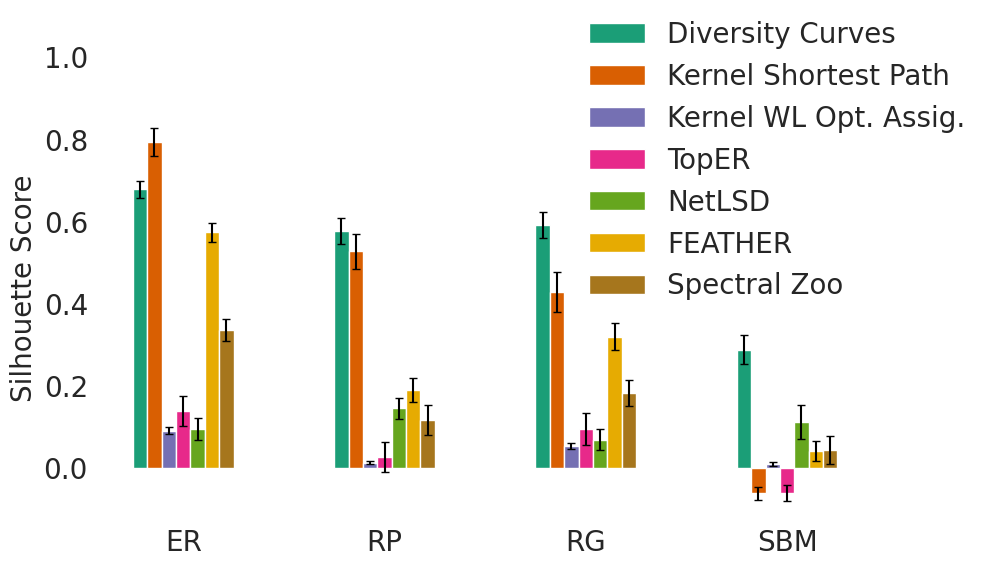

In [51]:
# manual selection from preselection
m_selection = [
    # 'divcurves_pca_shortest_path_distance',
    'divcurves_shortest_path_distance',
    'kernel_shortest_path',
    'kernel_weisfeiler_lehman_optimal_assignment',
    'toper_all_sub',
    'graph_embedding_netLSD',
    'graph_embedding_feathergraph',
    'spectral_zoo',
    # 'persistent_homology_vietoris_rips'
]

names_methods = {
    'divcurves_pca_shortest_path_distance': 'Diversity Curves',
    'divcurves_shortest_path_distance': 'Diversity Curves',
    'graph_embedding_feathergraph': 'FEATHER',
    # 'kernel_core_framework',
    'kernel_shortest_path': 'Kernel Shortest Path',
    'kernel_weisfeiler_lehman_optimal_assignment': 'Kernel WL Opt. Assig.',
    'toper_forricci_sub': 'TopER Forricci',
    'spectral_zoo': 'Spectral Zoo',
    'persistent_homology_alpha_complex': 'PH Alpha Complex',
    'persistent_homology_vietoris_rips': 'PH Vietoris Rips',
    'toper_all_sub': 'TopER',
    'graph_embedding_netLSD': 'NetLSD',
}

m_models = ['ER', 'RPG', 'RG', 'SBM']

selected = res_df.loc[m_selection,(m_models, slice(None))]

y=selected.loc[:, (slice(None), [f'{score}_mean'])].droplevel(level=1, axis=1)
y_err = selected.loc[:, (slice(None), [f'{score}_std'])].droplevel(level=1, axis=1)


matplotlib.rcParams.update({'font.size': 20})
# Assuming y and y_err are DataFrames with columns ['ER', 'BA', 'SBM']
# and multiple rows

fig, ax = plt.subplots(figsize=(10, 6))

# Get the models (column names)
# models = y.columns  # ['ER', 'BA', 'SBM']
models = ['ER', 'RP', 'RG', 'SBM']
n_rows = len(y)
x_positions = np.arange(len(models))

# Width for offsetting errorbars within each model group
bar_width = 0.5 / n_rows  # Adjust divisor to control spacing

# Colors for each row
colors = plt.cm.Dark2(X=range(n_rows))
# colors = plt.cm.tab10(X=range(n_rows))

bars = {}

# Plot errorbars for each row
for row_idx, row_name in enumerate(y.index):
    offsets = x_positions + (row_idx - n_rows/2 + 0.5) * bar_width
    ax.errorbar(
        offsets, 
        y.iloc[row_idx],
        yerr=y_err.iloc[row_idx],
        fmt='none',
        label=row_name,
        color='black',
        capsize=3,
        markersize=6
    )
    bars[row_name] = ax.bar(offsets, y.iloc[row_idx], width=bar_width, color=colors[row_idx])

ax = plt.gca()
ax.set_xticks(x_positions)
ax.set_xticklabels(models)
# ax.set_xlabel('Model')
# ax.set_ylabel(score)
ax.set_ylabel('Silhouette Score')
ax.set_ylim( top=1) #bottom=-1,
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(False)
box = ax.get_position()
# ax.set_position([box.x0, box.y0, box.width * 0.75, box.height])

ax.legend(handles = [bars[row] for row in y.index],
           labels=[names_methods[row] for row in y.index],
           frameon=False,
           loc=(0.62, 0.45),
            # bbox_to_anchor=(1, 0.5)  
           )

# ax.grid(axis='y', alpha=0.3)
# ax.grid(axis='x', visible=False)
# plt.tight_layout()
ax.tick_params(axis='x', which='both', bottom=False, top=False, left=False, right=False, labelbottom=True, labelleft=False)

plt.show()

# plt.savefig(f'output/ER_RPG_RG_SBM_{score}.pdf', dpi=300, format='pdf', bbox_inches="tight")